In [28]:
# качаем датасет
# он лежит тут: https://www.kaggle.com/datasets/CooperUnion/anime-recommendations-database?resource=download

import kagglehub

# Download latest version
path = kagglehub.dataset_download("CooperUnion/anime-recommendations-database", output_dir="./dataset/anime")

print("Path to dataset files:", path)

Path to dataset files: ./dataset/anime


## EDA

`rating.csv` содержит пары пользователь–аниме и оценку от 1 до 10. Значение -1 означает, что пользователь посмотрел аниме, но не поставил оценку. `anime.csv` содержит названия, жанры, тип, число эпизодов, среднюю оценку и количество пользователей, добавивших аниме себе в списки. Объект — аниме, взаимодействие — просмотр. 

Проверяем качество данных и делаем выборку

In [29]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

data_dir = Path(path)
anime = pd.read_csv(data_dir / "anime.csv")
ratings = pd.read_csv(data_dir / "rating.csv")

# в episodes иногда встречается unknown, заменим его на NaN
anime["episodes_num"] = pd.to_numeric(anime["episodes"], errors="coerce")

pd.DataFrame({
    "table": ["anime.csv", "rating.csv"],
    'rows': [len(anime), len(ratings)],
    'columns': [len(anime.columns) - 1, len(ratings.columns)],
})

,table,rows,columns
0,anime.csv,12294,7
1,rating.csv,7813737,3


In [30]:
anime.head(3)

,anime_id,name,genre,type,episodes,rating,members,episodes_num
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630,1.0
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665,64.0
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262,51.0


In [ ]:
# проверяем пропуски, дубликаты пар и соответствие идентификаторов списку аниме
anime_missing = anime.isna().sum().rename("missing").to_frame()
ratings_missing = ratings.isna().sum().rename("missing").to_frame()
duplicate_pairs = ratings.duplicated(["user_id", "anime_id"]).sum()
unknown_anime = ~ratings["anime_id"].isin(anime["anime_id"])
print(f"users: {ratings.user_id.nunique()}")
print(f"anime in connections: {ratings.anime_id.nunique()}")
print(f"duplicate user-anime pairs: {duplicate_pairs}")
print(f"interactions without anime metadata: {unknown_anime.sum()}")
print(f"unknown anime IDs: {ratings.loc[unknown_anime, 'anime_id'].nunique()}")

users: 73515
anime in connections: 11200
duplicate user-anime pairs: 7
interactions without anime metadata: 10
unknown anime IDs: 3


In [32]:
anime_missing.rename_axis("anime.csv")

,missing
anime.csv,
anime_id,0
name,0
genre,62
type,25
episodes,0
rating,230
members,0
episodes_num,340


In [33]:
ratings_missing.rename_axis("rating.csv")

,missing
rating.csv,
user_id,0
anime_id,0
rating,0


In [34]:
# смотрим распределение личных оценок: -1 — просмотр без оценки
rating_counts = ratings["rating"].value_counts().sort_index()

In [35]:
rating_counts.rename_axis("rating").to_frame("interactions")

,interactions
rating,
-1,1476496
1,16649
2,23150
3,41453
4,104291
5,282806
6,637775
7,1375287
8,1646019


watched without rating share: 18.9%


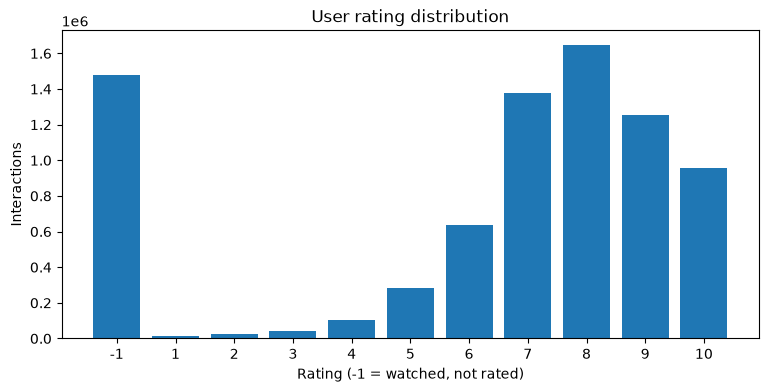

In [36]:
print(f"watched without rating share: {(ratings.rating == -1).mean():.1%}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(rating_counts.index.astype(str), rating_counts.values)
ax.set(title="User rating distribution", xlabel="Rating (-1 = watched, not rated)", ylabel="Interactions")
plt.show()

In [37]:
# оцениваем активность пользователей и популярность аниме
user_degree = ratings.groupby("user_id").size()
item_degree = ratings.groupby("anime_id").size()
degree_quantiles = pd.DataFrame({
    "user_interactions": user_degree.quantile([0, .10, .25, .50, .75, .90, .99, 1]),
    "item_interactions": item_degree.quantile([0, .10, .25, .50, .75, .90, .99, 1]),
})

In [38]:
degree_quantiles.rename_axis("quantile")

,user_interactions,item_interactions
quantile,,
0.00,1.00,1.00
0.10,5.00,1.00
0.25,18.00,5.00
0.50,57.00,51.50
0.75,136.00,385.25
0.90,260.00,1812.50
0.99,707.86,9968.55
1.00,10227.00,39340.00


full matrix density: 0.949%
interaction share of top 2000 anime: 87.7%


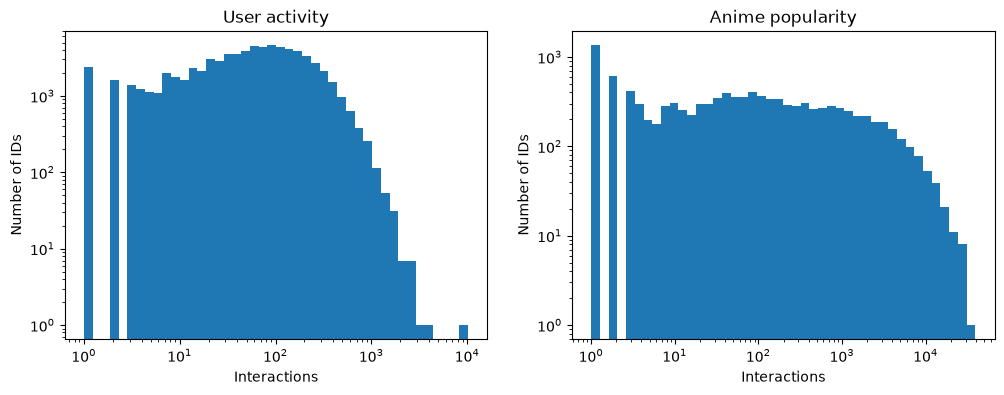

In [39]:
print(f"full matrix density: {len(ratings) / (ratings.user_id.nunique() * ratings.anime_id.nunique()):.3%}")
print(f"interaction share of top 2000 anime: {item_degree.nlargest(2000).sum() / len(ratings):.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, degree, title in zip(axes, [user_degree, item_degree], ["User activity", "Anime popularity"]):
    ax.hist(degree, bins=np.geomspace(1, degree.max() + 1, 45))
    ax.set(xscale="log", yscale="log", title=title, xlabel="Interactions", ylabel="Number of IDs")
plt.show()

In [40]:
# анализируем метаданные
type_counts = anime["type"].fillna("Unknown").value_counts()
genre_counts = anime["genre"].dropna().str.split(", ").explode().value_counts()
metadata_summary = pd.DataFrame({
    "missing_or_non_numeric": [anime.genre.isna().sum(), anime.type.isna().sum(), anime.episodes_num.isna().sum(), anime.rating.isna().sum()],
    "fraction": [anime.genre.isna().mean(), anime.type.isna().mean(), anime.episodes_num.isna().mean(), anime.rating.isna().mean()],
}, index=["genre", "type", "episodes", "rating"])

In [41]:
metadata_summary

,missing_or_non_numeric,fraction
genre,62,0.005043
type,25,0.002034
episodes,340,0.027656
rating,230,0.018708


genres: 43
median episodes: 2


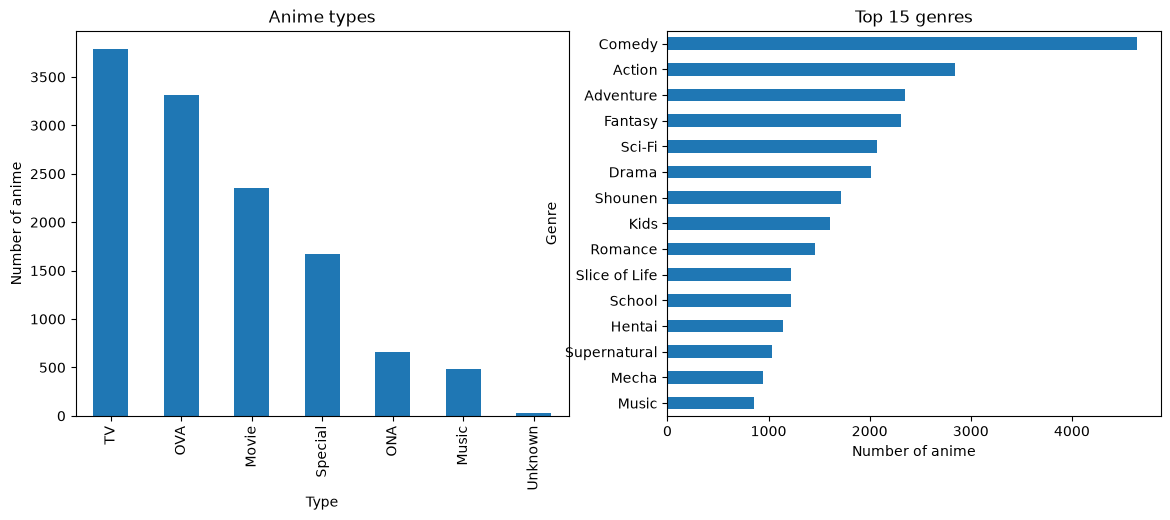

In [42]:
print(f"genres: {genre_counts.size}")
print(f"median episodes: {anime.episodes_num.median():.0f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
type_counts.plot.bar(ax=axes[0], title="Anime types")
genre_counts.head(15).sort_values().plot.barh(ax=axes[1], title="Top 15 genres")
axes[0].set(xlabel="Type", ylabel="Number of anime")
axes[1].set(xlabel="Number of anime", ylabel="Genre")
plt.show()

## Формируем выборку

- Повторные оценки одной пары сводим к максимальной. 
- Связи с отсутствующим в справочнике `anime_id` удаляем. 
- Случайно отбираем 15000 пользователей с 20-300 взаимодействиями. 
- Оставляем 2000 самых популярных среди них аниме и пользователей с хотя бы 10 оставшимися связями, чтобы матрица была плотнее и ограничить влияние активных пользователей.
- Оставляем метаданные `genre`, `type` и `episodes`. `rating` и `members` не используем как признаки, потому что они посчитаны по всему датасету, а не по нашей выборке

In [43]:
# убираем дубликаты и связи без метаданных, выбираем пользователей
RANDOM_SEED = 1000 - 7
MIN_USER_HISTORY = 20
MAX_USER_HISTORY = 300
N_SAMPLED_USERS = 15000
N_ITEMS = 2000
MIN_FINAL_HISTORY = 10

ratings_clean = ratings.groupby(["user_id", "anime_id"], as_index=False, sort=False)["rating"].max()
ratings_clean = ratings_clean[ratings_clean.anime_id.isin(anime.anime_id)].copy()
clean_user_degree = ratings_clean.groupby("user_id").size()
eligible_users = clean_user_degree.index[
    clean_user_degree.between(MIN_USER_HISTORY, MAX_USER_HISTORY)
]
rng = np.random.default_rng(RANDOM_SEED)
sampled_users = rng.permutation(eligible_users.to_numpy())[:N_SAMPLED_USERS]
ratings_sampled = ratings_clean[ratings_clean.user_id.isin(sampled_users)].copy()
print(f"after cleaning: {len(ratings_clean)} interactions")
print(f"eligible users: {len(eligible_users)}")
print(f"sampled users: {ratings_sampled.user_id.nunique()}")
print(f"interactions before item selection: {len(ratings_sampled)}")

after cleaning: 7813720 interactions
eligible users: 48450
sampled users: 15000
interactions before item selection: 1480193


In [44]:
# оставляем 2000 самых популярных аниме и пользователей с достаточной историей
sampled_item_degree = ratings_sampled.groupby("anime_id").size()
top_anime_ids = sampled_item_degree.sort_values(ascending=False, kind="stable").head(N_ITEMS).index
ratings_prepared = ratings_sampled[ratings_sampled.anime_id.isin(top_anime_ids)].copy()
final_user_degree = ratings_prepared.groupby("user_id").size()
kept_users = final_user_degree.index[final_user_degree >= MIN_FINAL_HISTORY]
ratings_prepared = ratings_prepared[ratings_prepared.user_id.isin(kept_users)].copy()
ratings_prepared = ratings_prepared.sort_values(["user_id", "anime_id"]).reset_index(drop=True)
anime_prepared = anime[anime.anime_id.isin(ratings_prepared.anime_id)].copy()

n_users = ratings_prepared.user_id.nunique()
n_items = ratings_prepared.anime_id.nunique()
n_interactions = len(ratings_prepared)

In [45]:
pd.DataFrame({
    "metric": ["Interactions", "Users", "Anime", "Matrix density", "Watched without rating share"],
    "value": [f"{n_interactions}", f"{n_users}", f"{n_items}", f"{n_interactions / (n_users * n_items):.3%}", f"{(ratings_prepared.rating == -1).mean():.1%}"],
})

,metric,value
0,Interactions,1360867
1,Users,14994
2,Anime,2000
3,Matrix density,4.538%
4,Watched without rating share,17.9%


In [46]:
anime_prepared[["genre", "type", "episodes_num"]].isna().sum().rename("missing_in_selected_anime")

genre           0
type            0
episodes_num    0
Name: missing_in_selected_anime, dtype: int64

In [47]:
# проверяем распределения связей в итоговой выборке и размер матрицы для моделей
final_user_degree = ratings_prepared.groupby("user_id").size()
final_item_degree = ratings_prepared.groupby("anime_id").size()

In [48]:
pd.DataFrame({
    "user_interactions": final_user_degree.quantile([0, .10, .50, .90, .99, 1]),
    "item_interactions": final_item_degree.quantile([0, .10, .50, .90, .99, 1]),
}).rename_axis("quantile")

,user_interactions,item_interactions
quantile,,
0.00,10.0,112.00
0.10,26.0,141.00
0.50,72.0,363.00
0.90,188.0,1583.50
0.99,262.0,4415.32
1.00,292.0,9286.00


user-anime matrix size: 14994 × 2000


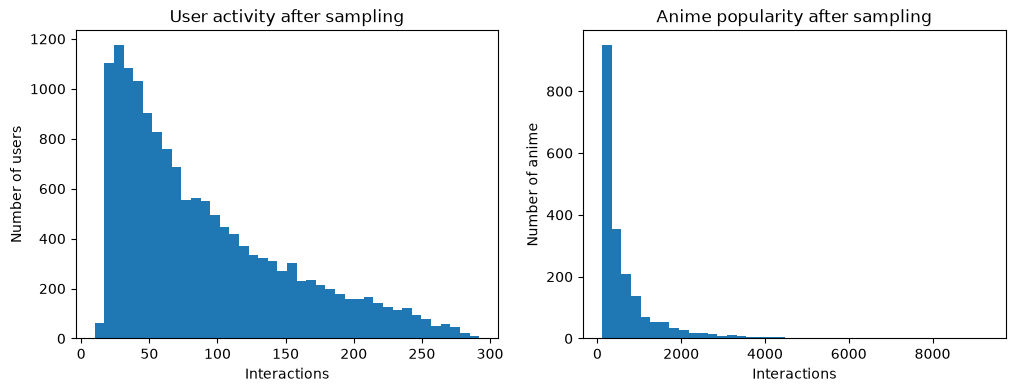

In [49]:
print(f"user-anime matrix size: {n_users} × {n_items}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(final_user_degree, bins=40)
axes[1].hist(final_item_degree, bins=40)
axes[0].set(title="User activity after sampling", xlabel="Interactions", ylabel="Number of users")
axes[1].set(title="Anime popularity after sampling", xlabel="Interactions", ylabel="Number of anime")
plt.show()

## Итог

В датасете 7813737 связей - больше чем 2000000. В итоговой выборке 1360867 связей, 14994 пользователей и 2000 аниме. Для выбранных аниме заполнены `genre`, `type` и число эпизодов. Выбор популярных аниме повышает плотность матрицы до 4.538%, но уменьшает охват редких объектов.

## Протокол оценки

В данных нет времени просмотра, поэтому используем случайное разбиение отдельно для каждого пользователя. В validation и test откладываем по 10% аниме с оценкой от 7 до 10 (такие аниме считаем релевантными), но не меньше одного. Пользователи с менее чем тремя такими оценками остаются только в train. Оценки от 1 до 6 и просмотры без оценки остаются в train - не факт что они релевантные.

Для всех моделей используем одно разбиение и считаем релевантными одни и те же аниме. Подбираем параметры на validation. После выбора параметров обучаем модель на train и validation и один раз оцениваем на test.

In [50]:
# откладываем положительные оценки для validation и test
positive = ratings_prepared[ratings_prepared.rating >= 7]
rng = np.random.default_rng(RANDOM_SEED)
validation_indices = []
test_indices = []

for user_id, user_positive in positive.groupby("user_id"):
    if len(user_positive) < 3:
        continue
    n_holdout = max(1, len(user_positive) // 10)
    shuffled_indices = rng.permutation(user_positive.index.to_numpy())
    validation_indices.extend(shuffled_indices[:n_holdout])
    test_indices.extend(shuffled_indices[n_holdout:2 * n_holdout])

validation = ratings_prepared.loc[validation_indices].reset_index(drop=True)
test = ratings_prepared.loc[test_indices].reset_index(drop=True)
train = ratings_prepared.drop(index=validation_indices + test_indices).reset_index(drop=True)
train_validation = pd.concat([train, validation], ignore_index=True)

pd.DataFrame({
    "split": ["train", "validation", "test"],
    "interactions": [len(train), len(validation), len(test)],
    "users": [train.user_id.nunique(), validation.user_id.nunique(), test.user_id.nunique()],
    "anime": [train.anime_id.nunique(), validation.anime_id.nunique(), test.anime_id.nunique()],
})

,split,interactions,users,anime
0,train,1181043,14994,2000
1,validation,89912,13919,1999
2,test,89912,13919,1998


Кандидаты для каждого пользователя — все аниме, встречающиеся в train. В validation исключаем уже известные пользователю аниме из train. В test после повторного обучения исключаем известные аниме из train и validation. Неизвестные пользователи не входят в оценку. Аниме без взаимодействий в train не входят в набор кандидатов. Показываем, сколько таких случаев возникло.

Основная метрика — NDCG@10: она учитывает позиции релевантных аниме в первой десятке. Дополнительная метрика — Recall@10: она показывает долю найденных релевантных аниме.

In [51]:
# фиксируем общих кандидатов и пользователей для всех моделей
candidate_items = np.sort(train.anime_id.unique())
validation_cold = ~validation.anime_id.isin(candidate_items)
test_cold = ~test.anime_id.isin(candidate_items)

validation_eval = validation.loc[~validation_cold].copy()
test_eval = test.loc[~test_cold].copy()
evaluation_users = np.intersect1d(validation_eval.user_id.unique(), test_eval.user_id.unique())
validation_eval = validation_eval[validation_eval.user_id.isin(evaluation_users)].copy()
test_eval = test_eval[test_eval.user_id.isin(evaluation_users)].copy()

train_seen = train.groupby("user_id").anime_id.agg(set).to_dict()
train_validation_seen = train_validation.groupby("user_id").anime_id.agg(set).to_dict()

def get_candidates(user_id, seen_by_user):
    return np.setdiff1d(candidate_items, list(seen_by_user.get(user_id, set())), assume_unique=True)

pd.DataFrame({
    "metric": [
        "candidate anime", "evaluation users", "cold validation interactions",
        "cold test interactions", "excluded validation users", "excluded test users",
    ],
    "value": [
        len(candidate_items), len(evaluation_users), validation_cold.sum(),
        test_cold.sum(), validation.user_id.nunique() - len(evaluation_users),
        test.user_id.nunique() - len(evaluation_users),
    ],
})

,metric,value
0,candidate anime,2000
1,evaluation users,13919
2,cold validation interactions,0
3,cold test interactions,0
4,excluded validation users,0
5,excluded test users,0


In [52]:
# считаем одинаковые метрики для списков рекомендаций всех моделей
def ranking_metrics(recommended, relevant):
    relevant = set(relevant)
    hits = np.array([item in relevant for item in recommended[:10]], dtype=float)
    recall = hits.sum() / len(relevant)
    discount = 1 / np.log2(np.arange(len(hits)) + 2)
    ideal_discount = 1 / np.log2(np.arange(min(10, len(relevant))) + 2)
    ndcg = (hits * discount).sum() / ideal_discount.sum()
    return ndcg, recall


def evaluate_top10(score_fn, targets, seen_by_user):
    results = []
    for user_id, user_targets in targets.groupby("user_id"):
        candidates = get_candidates(user_id, seen_by_user)
        scores = np.asarray(score_fn(user_id, candidates))
        if scores.shape != candidates.shape:
            raise ValueError("score_fn must return one score per candidate")
        recommended = candidates[np.argsort(-scores, kind="stable")[:10]]
        results.append(ranking_metrics(recommended, user_targets.anime_id))

    mean_ndcg, mean_recall = np.mean(results, axis=0)
    return {"NDCG@10": float(mean_ndcg), "Recall@10": float(mean_recall)}


## Модели

Все модели в итоге выдают score для каждого аниме. По нему сортируем рекомендации. Аниме, которые пользователь уже смотрел, убираем отдельно

- **ItemCF.** Сначала смотрим, какие аниме пользователи оценили на 7–10. Если два аниме нравятся одним и тем же людям, считаем их похожими. Сходство считаем как `cooc / sqrt(pop_i * pop_j) * cooc / (cooc + shrinkage)`. Здесь `cooc` — сколько пользователей положительно оценили оба аниме, а `pop` — сколько положительных оценок есть у каждого из них. Поправка `shrinkage` уменьшает сходство, которое получилось из малого числа общих пользователей. Для каждого аниме оставляем `neighbors` ближайших соседей. Score кандидата — сумма его сходств с аниме, которые понравились пользователю.
- **ImplicitALS.** Представляем пользователя и аниме векторами и подбираем их так, чтобы их скалярное произведение совпадало с целевым сигналом. Ошибка имеет вид `sum_ui c_ui * (p_ui - x_u @ y_i)^2` плюс L2-регуляризация. Любую связь из train, даже просмотр без оценки, считаем положительной: `p_ui = 1` и `c_ui = 1 + alpha`. Для остальных пар `p_ui = 0` и `c_ui = 1`. По очереди обновляем векторы пользователей и аниме.
- **EASE.** Бинарная матрица `X`, где 1 означает оценку от 7 до 10, а 0 -- все остальное. Модель учится восстанавливать понравившиеся аниме по другим понравившимся аниме пользователя. Считаем `P = (X.T @ X + regularization * I)^(-1)` и затем `B_ij = -P_ij / P_jj`. Диагональ `B` обнуляем, чтобы аниме не предсказывало само себя. Score получаем как `X_u @ B`.
- **FM.** На вход подаём ID пользователя и аниме, жанры, тип и `log(1 + episodes)` аниме. Модель учитывает и отдельные признаки, и их попарные сочетания: `b + w @ x + 0.5 * sum_f((sum_i V_if * x_i)^2 - sum_i V_if^2 * x_i^2)`. Оценки 7–10 считаем положительными примерами. Оценки 1–6 и случайно выбранные непросмотренные аниме считаем отрицательными. Просмотры с `rating = -1` не используем как размеченные примеры. `rating` и `members` из `anime.csv` не берём в признаки: они посчитаны по всему датасету.
- **RatingALS.** Это тот же ALS, но используем оценку пользователя: `p_ui = max(0, (r - 6) / 4)`. Оценки 1–6 дают 0, оценки 7–10 дают значения от 0.25 до 1. Для оценённых связей `c_ui = 1 + alpha`. Просмотр без оценки получает `p_ui = 0` и `c_ui = 1`. Так модель может отличать высокую оценку от низкой.


## Подбор моделей

Основная метрика — NDCG@10, плюс Recall@10. Для каждой модели проверяем настройки на одних и тех же пользователях и кандидатах validation. Побеждает настройка с максимальной NDCG@10.

- ItemCF: 50 или 150 соседей, поправка на малое число общих просмотров 0 или 100.
- iALS и RatingALS: 16 или 32 фактора, `alpha` 10 или 40. Число итераций 5, регуляризация 0.1.
- EASE: регуляризация 50, 200 или 800.
- FM: 8 или 16 факторов, регуляризация 0.0001 или 0.001. Число эпох 3, по одному случайному непросмотренному аниме на положительный пример.

In [53]:
# задаем классы моделей и небольшие сетки параметров
from itertools import product

from models import EASE, FactorizationMachine, ImplicitALS, ItemCF, RatingALS

model_classes = {
    "ItemCF": ItemCF,
    "ImplicitALS": ImplicitALS,
    "EASE": EASE,
    "FM": FactorizationMachine,
    "RatingALS": RatingALS,
}

search_space = {
    "ItemCF": [
        {"neighbors": neighbors, "shrinkage": shrinkage}
        for neighbors, shrinkage in product([50, 150], [0, 100])
    ],
    "ImplicitALS": [
        {"factors": factors, "alpha": alpha, "iterations": 5,
         "regularization": 0.1, "seed": RANDOM_SEED}
        for factors, alpha in product([16, 32], [10, 40])
    ],
    "EASE": [
        {"regularization": regularization}
        for regularization in [50, 200, 800]
    ],
    "FM": [
        {"factors": factors, "regularization": regularization,
         "epochs": 3, "negative_ratio": 1, "seed": RANDOM_SEED}
        for factors, regularization in product([8, 16], [0.0001, 0.001])
    ],
    "RatingALS": [
        {"factors": factors, "alpha": alpha, "iterations": 5,
         "regularization": 0.1, "seed": RANDOM_SEED}
        for factors, alpha in product([16, 32], [10, 40])
    ],
}

pd.DataFrame({
    "model": list(search_space),
    "configurations": [len(settings) for settings in search_space.values()],
})

,model,configurations
0,ItemCF,4
1,ImplicitALS,4
2,EASE,3
3,FM,4
4,RatingALS,4


In [54]:
# обучаем каждую настройку на train и сравниваем на validation
validation_results = []
best_params = {}
best_validation = {}

for model_name, settings in search_space.items():
    for params in settings:
        model = model_classes[model_name](**params)
        model.fit(train, anime_prepared)
        metrics = evaluate_top10(model.score, validation_eval, train_seen)
        validation_results.append({"model": model_name, "params": params, **metrics})
        if model_name not in best_validation or metrics["NDCG@10"] > best_validation[model_name]["NDCG@10"]:
            best_params[model_name] = params
            best_validation[model_name] = metrics

validation_results_df = pd.DataFrame(validation_results)
validation_results_df.sort_values(["model", "NDCG@10"], ascending=[True, False]).reset_index(drop=True)

,model,params,NDCG@10,Recall@10
0,EASE,{'regularization': 50},0.334514,0.347783
1,EASE,{'regularization': 200},0.332257,0.348053
2,EASE,{'regularization': 800},0.312591,0.331395
3,FM,"{'factors': 16, 'regularization': 0.0001, 'epo...",0.081731,0.088589
4,FM,"{'factors': 16, 'regularization': 0.001, 'epoc...",0.081312,0.089018
5,FM,"{'factors': 8, 'regularization': 0.0001, 'epoc...",0.081164,0.089294
6,FM,"{'factors': 8, 'regularization': 0.001, 'epoch...",0.081101,0.088515
7,ImplicitALS,"{'factors': 32, 'alpha': 10, 'iterations': 5, ...",0.220399,0.245055
8,ImplicitALS,"{'factors': 16, 'alpha': 10, 'iterations': 5, ...",0.199718,0.219866
9,ImplicitALS,"{'factors': 32, 'alpha': 40, 'iterations': 5, ...",0.163802,0.199475


Отдельно обучаем FM с теми же выбранными параметрами, но без метаданных. Сравниваем оба варианта на validation. Просто ради интереса

In [55]:
# сравниваем FM с метаданными и без них на validation
fm_without_metadata = FactorizationMachine(**best_params["FM"], use_metadata=False)
fm_without_metadata.fit(train, anime_prepared)
fm_id_metrics = evaluate_top10(fm_without_metadata.score, validation_eval, train_seen)

pd.DataFrame([
    {"features": "ID and metadata", **best_validation["FM"]},
    {"features": "ID only", **fm_id_metrics},
])

,features,NDCG@10,Recall@10
0,ID and metadata,0.081731,0.088589
1,ID only,0.087736,0.093564


## Финальная оценка

Для каждой из пяти моделей берем параметры, выбранные по NDCG@10 на validation. Обучаем заново на train и validation. Затем один раз оцениваем на test с теми же правилами исключения известных аниме.

In [56]:
# переобучаем выбранные модели и один раз оцениваем на test
comparison_rows = []
for model_name, params in best_params.items():
    model = model_classes[model_name](**params)
    model.fit(train_validation, anime_prepared)
    test_metrics = evaluate_top10(model.score, test_eval, train_validation_seen)
    comparison_rows.append({
        "model": model_name,
        "params": params,
        "validation NDCG@10": best_validation[model_name]["NDCG@10"],
        "validation Recall@10": best_validation[model_name]["Recall@10"],
        "test NDCG@10": test_metrics["NDCG@10"],
        "test Recall@10": test_metrics["Recall@10"],
    })

comparison = pd.DataFrame(comparison_rows).sort_values(
    "test NDCG@10", ascending=False
).reset_index(drop=True)
comparison

,model,params,validation NDCG@10,validation Recall@10,test NDCG@10,test Recall@10
0,EASE,{'regularization': 50},0.334514,0.347783,0.428325,0.401273
1,ImplicitALS,"{'factors': 32, 'alpha': 10, 'iterations': 5, ...",0.220399,0.245055,0.252296,0.265931
2,RatingALS,"{'factors': 32, 'alpha': 10, 'iterations': 5, ...",0.188519,0.208226,0.214242,0.227957
3,ItemCF,"{'neighbors': 50, 'shrinkage': 0}",0.177049,0.192826,0.198709,0.205687
4,FM,"{'factors': 16, 'regularization': 0.0001, 'epo...",0.081731,0.088589,0.084937,0.092758


## Итоговая таблица

| Model | Selected parameters | Validation NDCG@10 | Validation Recall@10 | Test NDCG@10 | Test Recall@10 |
| --- | --- | --- | --- | --- | --- |
| EASE | `regularization=50` | 0.334514 | 0.347783 | 0.428325 | 0.401273 |
| ImplicitALS | `factors=32`, `alpha=10`, `iterations=5`, `regularization=0.1` | 0.220399 | 0.245055 | 0.252296 | 0.265931 |
| RatingALS | `factors=32`, `alpha=10`, `iterations=5`, `regularization=0.1` | 0.188519 | 0.208226 | 0.214242 | 0.227957 |
| ItemCF | `neighbors=50`, `shrinkage=0` | 0.177049 | 0.192826 | 0.198709 | 0.205687 |
| FM | `factors=16`, `regularization=0.0001`, `epochs=3`, `negative_ratio=1` | 0.081731 | 0.088589 | 0.084937 | 0.092758 |

Для FM оставлены `learning_rate=0.01` и `batch_size=4096`.

## Выводы

- EASE с регуляризацией 50 топовая по обеим метрикам: test NDCG@10 = 0.428325 и Recall@10 = 0.401273.
- Базовая ImplicitALS заняла второе место: test NDCG@10 = 0.252296. RatingALS получила 0.214242. То есть сигнал из оценок результат не улучшил.
- ItemCF получила test NDCG@10 = 0.198709. FM получила 0.084937 и оказалось самой худшей.
- Для FM метаданные снизили validation NDCG@10 с 0.087736 до 0.081731, что вообще говоря странно, но видимо потому что много популярных аниме.
- Метрики test выше validation у всех пяти моделей. Наверное потому что перед test модели получают больше взаимодействий в трейне, а из кандидатов исключаются дополнительные известные аниме.